# Advanced Pool-based Active Learning for Regression

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](<colab_link>)

> **Google Colab:** If imports fail after installation, select
> **Runtime → Restart session**, then run the notebook again.

Separate model choice from query-strategy choice when predicting superconductors' critical temperature. We adapt a random forest, XGBoost, and a PyTorch multilayer perceptron (MLP), then compare random sampling and improved greedy sampling with each model. All six combinations use the same numerical annotation loop, test split, and paired run seeds.

This notebook assumes the scikit-learn regressor interface, pool-based querying, and basic PyTorch training settings. The [regression introduction](02_pool_regression_getting_started.ipynb) explains missing labels and numerical annotation.

## Setup

Uncomment the installation command if needed, then run from a fresh kernel. The first run downloads the data from OpenML. Later runs reuse files under `.cache`.

In [1]:
# !pip install "scikit-activeml[opt]" torch skorch xgboost matplotlib tqdm

With `USE_GPU=True`, XGBoost and the MLP train on a GPU if one is available. Set `USE_CUML=False` to use the scikit-learn random forest directly. Without a GPU or cuML, the notebook also uses scikit-learn. Restart the kernel after changing this setting, because cuML must be activated before estimator imports.

In [2]:
import warnings

# At the zero-label checkpoint, the regressors predict a label mean of zero
# and warn, and XGBoost warns about its empty training set. On a GPU,
# XGBoost also notes once that it copies the NumPy inputs for prediction.
for message in [
    "The 'estimator' could not be fitted",
    "Since the 'estimator' could not be fitted",
    ".*Empty dataset at worker",
    ".*Falling back to prediction using DMatrix",
]:
    warnings.filterwarnings("ignore", message=message)

import torch

USE_GPU = True
USE_CUML = True
cuml_enabled = False

if USE_GPU and USE_CUML and torch.cuda.is_available():
    try:
        import cuml.accel

        cuml.accel.install(log_level="error")
        cuml_enabled = True
    except ImportError:
        pass

In [3]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats
import numpy as np

from sklearn.datasets import fetch_openml
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from skorch.callbacks import LRScheduler
from skorch.toy import MLPModule
from torch import nn
from torch.optim.lr_scheduler import CosineAnnealingLR
from tqdm import tqdm
from xgboost import XGBRegressor

from skactiveml.pool import (
    GreedySamplingTarget,
    RandomSampling,
    SubSamplingWrapper,
)
from skactiveml.regressor import SklearnRegressor, SkorchRegressor
from skactiveml.utils import MISSING_LABEL, call_func

plt.style.use("default")
plt.rcParams.update(
    {
        "font.size": 11,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "xtick.labelsize": 11,
        "ytick.labelsize": 11,
        "legend.fontsize": 10,
        "figure.titlesize": 12,
    }
)
set_matplotlib_formats("retina")

### Choose the Workload

`QUICK_RUN=False` selects the reference: all 21,263 samples split 80/20 into acquisition and test sets, three repetitions, and thirty acquisitions of 128 labels, reaching 3,840 acquired labels per trajectory. Every run starts without labels, and the MLP trains for 100 epochs at each refit. `QUICK_RUN=True` uses smaller datasets, five acquisitions, and five MLP epochs while retaining all six combinations.

The candidate cap of 1,000 controls selection work separately from the batch size.

In [4]:
QUICK_RUN = False
RANDOM_STATE = 0

query_batch_size = 128
n_candidates = 1000
CACHE_PATH = Path(".cache")

if QUICK_RUN:
    pool_limit = 4000
    test_limit = 1000
    n_reps = 2
    n_cycles = 5
    max_epochs = 5
else:
    pool_limit = None
    test_limit = None
    n_reps = 3
    n_cycles = 30
    max_epochs = 100

device = "cuda" if USE_GPU and torch.cuda.is_available() else "cpu"
label_counts = np.arange(n_cycles + 1) * query_batch_size

## Prepare the Regression Data

The [superconductivity dataset](https://archive.ics.uci.edu/dataset/464/superconductivty+data) has 81 numerical features and critical temperature as its label. We load its [OpenML copy](https://www.openml.org/d/43174) and reserve 20% of the samples for testing with split seed zero. Quick execution selects seeded subsets within each split without using their labels.

Fit `StandardScaler` on pool features only and use it to transform both sets. All unlabeled pool features are available for preprocessing. Scaling gives the MLP comparable feature scales and keeps feature units from dominating GSi's Euclidean distances. Test samples remain outside preprocessing fits, model fits, and queries.

In [5]:
X_full, y_full = fetch_openml(
    data_id=43174,
    return_X_y=True,
    data_home=str(CACHE_PATH),
    as_frame=False,
)
X_full = np.asarray(X_full, dtype=float)
y_full = np.asarray(y_full, dtype=float)

X_pool, X_test, y_pool_true, y_test = train_test_split(
    X_full, y_full, test_size=0.2, random_state=RANDOM_STATE
)

if QUICK_RUN:
    subset_rng = np.random.RandomState(RANDOM_STATE)
    pool_indices = subset_rng.permutation(len(X_pool))[:pool_limit]
    test_indices = subset_rng.permutation(len(X_test))[:test_limit]
    X_pool, y_pool_true = X_pool[pool_indices], y_pool_true[pool_indices]
    X_test, y_test = X_test[test_indices], y_test[test_indices]

scaler = StandardScaler().fit(X_pool)
X_pool = scaler.transform(X_pool)
X_test = scaler.transform(X_test)
n_features = X_pool.shape[1]

### Keep Acquired and Hidden Labels Separate

`y_pool_true` simulates an oracle whose labels are revealed only when requested. Each run creates a separate `y` vector filled with `MISSING_LABEL` (`np.nan`). A missing entry means an unknown label, so a measured temperature of zero remains a valid label. Only `y` is passed to fitting and querying. `y_test` is used only for evaluation.

A query returns row indices into `X_pool`. Filling `y[query_idx]` with the corresponding labels records them without moving samples. Replace that lookup with your measurement or labeling process when adapting the workflow.

## Configure the Regression Models

`SklearnRegressor` wraps the random forest and XGBoost, excluding missing labels from fitting. `SkorchRegressor` gives the PyTorch MLP the same `fit`, `predict`, and `score` interface. Its prediction transform removes the final output dimension while preserving one prediction per sample.

The tree estimators keep their default model parameters. The MLP has two hidden layers of 256 units and dropout probability 0.1. It uses Huber loss, RAdam, and a cosine learning-rate schedule. Each factory creates a fresh regressor for one run. Every `fit` retrains on all acquired labels. With `warm_start=False`, it also reinitializes the MLP and its schedule, following the [skorch fitting contract](https://skorch.readthedocs.io/en/stable/user/neuralnet.html#warm-start).

In [6]:
tree_worker_params = {"n_jobs": 1} if QUICK_RUN else {}
regressor_dict = {
    "RF": lambda seed: SklearnRegressor(
        RandomForestRegressor(random_state=seed, **tree_worker_params),
        random_state=seed,
    ),
    "XGBoost": lambda seed: SklearnRegressor(
        XGBRegressor(
            device=device, random_state=seed, **tree_worker_params
        ),
        random_state=seed,
    ),
    "MLP": lambda seed: SkorchRegressor(
        module=MLPModule,
        criterion=nn.HuberLoss,
        forward_outputs={"prediction": (0, lambda pred: pred.squeeze(-1))},
        neural_net_param_dict={
            "module__input_units": n_features,
            "module__output_units": 1,
            "module__hidden_units": 256,
            "module__num_hidden": 2,
            "module__dropout": 0.1,
            "max_epochs": max_epochs,
            "batch_size": 128,
            "optimizer": torch.optim.RAdam,
            "optimizer__lr": 1e-2,
            "callbacks": [
                (
                    "lr_scheduler",
                    LRScheduler(policy=CosineAnnealingLR, T_max=max_epochs),
                )
            ],
            "verbose": 0,
            "device": device,
            "train_split": None,
            "warm_start": False,
            "iterator_train__shuffle": True,
            "torch_load_kwargs": {"weights_only": True},
        },
        sample_dtype=np.float32,
        missing_label=MISSING_LABEL,
        random_state=seed,
    ),
}

## Configure Query Strategies

`RandomSampling` selects without model predictions and provides a reference for judging selection. `GreedySamplingTarget(method="GSi")` combines feature-space and label-space distances. The [greedy sampling paper](https://arxiv.org/abs/1808.04245) calls this improved greedy sampling (iGS). The library uses `"GSi"`. It favors candidates with a large minimum product of those distances to labeled samples and samples already selected in the batch. Label distances use acquired labels and predictions for unlabeled candidates. With the default `n_GSx_samples=1`, the first selection uses feature distances alone when starting without labels. Later selections in that batch also use the initial model's predictions.

`SubSamplingWrapper` considers at most 1,000 unlabeled candidates per query and retains labeled samples for the strategy. Setting `exclude_non_subsample=True` excludes the other unlabeled samples from the wrapped query.

In [7]:
query_strategy_dict = {
    "Random sampling": lambda seed: RandomSampling(random_state=seed),
    "GSi": lambda seed: GreedySamplingTarget(
        method="GSi", random_state=seed
    ),
}

## Run the Study

For each model–strategy combination, query a batch, acquire only its labels, fit the regressor, and score on the held-out test set. `fit_reg=False` reuses the fitted regressor during selection. `call_func` forwards the arguments accepted by each strategy, so random sampling and GSi share this loop. The final batch is fitted and scored, giving 31 checkpoints from zero to 3,840 labels in the reference configuration.

At zero labels, wrapped tree models either accept an empty fit or use `SklearnRegressor`'s zero-mean fallback. The MLP predicts with its initialized, untrained network. These initial scores describe starting predictions, and GSi uses them for label distances in its first batch.

Within a repetition, every combination uses `RANDOM_STATE + repetition` for its model, strategy, and candidate subsampling, and resets PyTorch's seed. Fresh objects prevent state from carrying between runs. Once strategies acquire different labels, their remaining pools and later candidate subsets can differ. All runs share the same data split. Each `results` array has shape `(n_reps, n_cycles + 1)`, with rows for repetitions and columns for annotation checkpoints.

In [8]:
results = {}
for reg_name, make_regressor in regressor_dict.items():
    for qs_name, make_strategy in query_strategy_dict.items():
        combination = f"{reg_name}-{qs_name}"
        r2_scores = np.full((n_reps, n_cycles + 1), np.nan)

        with tqdm(
            total=n_reps * n_cycles,
            desc=combination,
            file=sys.stdout,
            ascii=True,
            ncols=79,
            mininterval=20,
            leave=True,
        ) as progress:
            for repetition in range(n_reps):
                seed = RANDOM_STATE + repetition
                torch.manual_seed(seed)
                y = np.full_like(y_pool_true, MISSING_LABEL)
                reg = make_regressor(seed)
                qs = SubSamplingWrapper(
                    make_strategy(seed),
                    max_candidates=n_candidates,
                    exclude_non_subsample=True,
                    random_state=seed,
                )

                reg.fit(X_pool, y)
                r2_scores[repetition, 0] = reg.score(X_test, y_test)

                for cycle in range(1, n_cycles + 1):
                    query_idx = call_func(
                        qs.query,
                        X=X_pool,
                        y=y,
                        batch_size=query_batch_size,
                        reg=reg,
                        fit_reg=False,
                    )
                    # Replace this lookup with your annotation process.
                    y[query_idx] = y_pool_true[query_idx]
                    reg.fit(X_pool, y)
                    r2_scores[repetition, cycle] = reg.score(X_test, y_test)
                    progress.update(1)

        results[combination] = r2_scores

MLP-GSi: 100%|#################################| 90/90 [03:19<00:00,  2.21s/it]


## Compare Learning Curves

[Test R²](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.r2_score.html) compares squared prediction error with that of a constant predictor equal to the test-label mean. Perfect predictions give R² = 1, and that constant reference gives R² = 0. Negative scores indicate larger squared error than the reference. The test mean is used only in evaluation.

Each model has a row below. The left panel shows test R² from the first acquisition on. Without labels, every model predicts zero and scores about −1, which would compress the curves. The right panel shows GSi's gain over random sampling at each annotation budget. Compare strategies within a row before comparing model families across rows. Lines show means across repetitions, and shading shows one sample standard deviation (`ddof=1`). Gains are computed within matching repetitions before aggregation. These bands describe run variation on one fixed split, rather than confidence intervals or variation across datasets. Legend values average R² across the budgets shown.

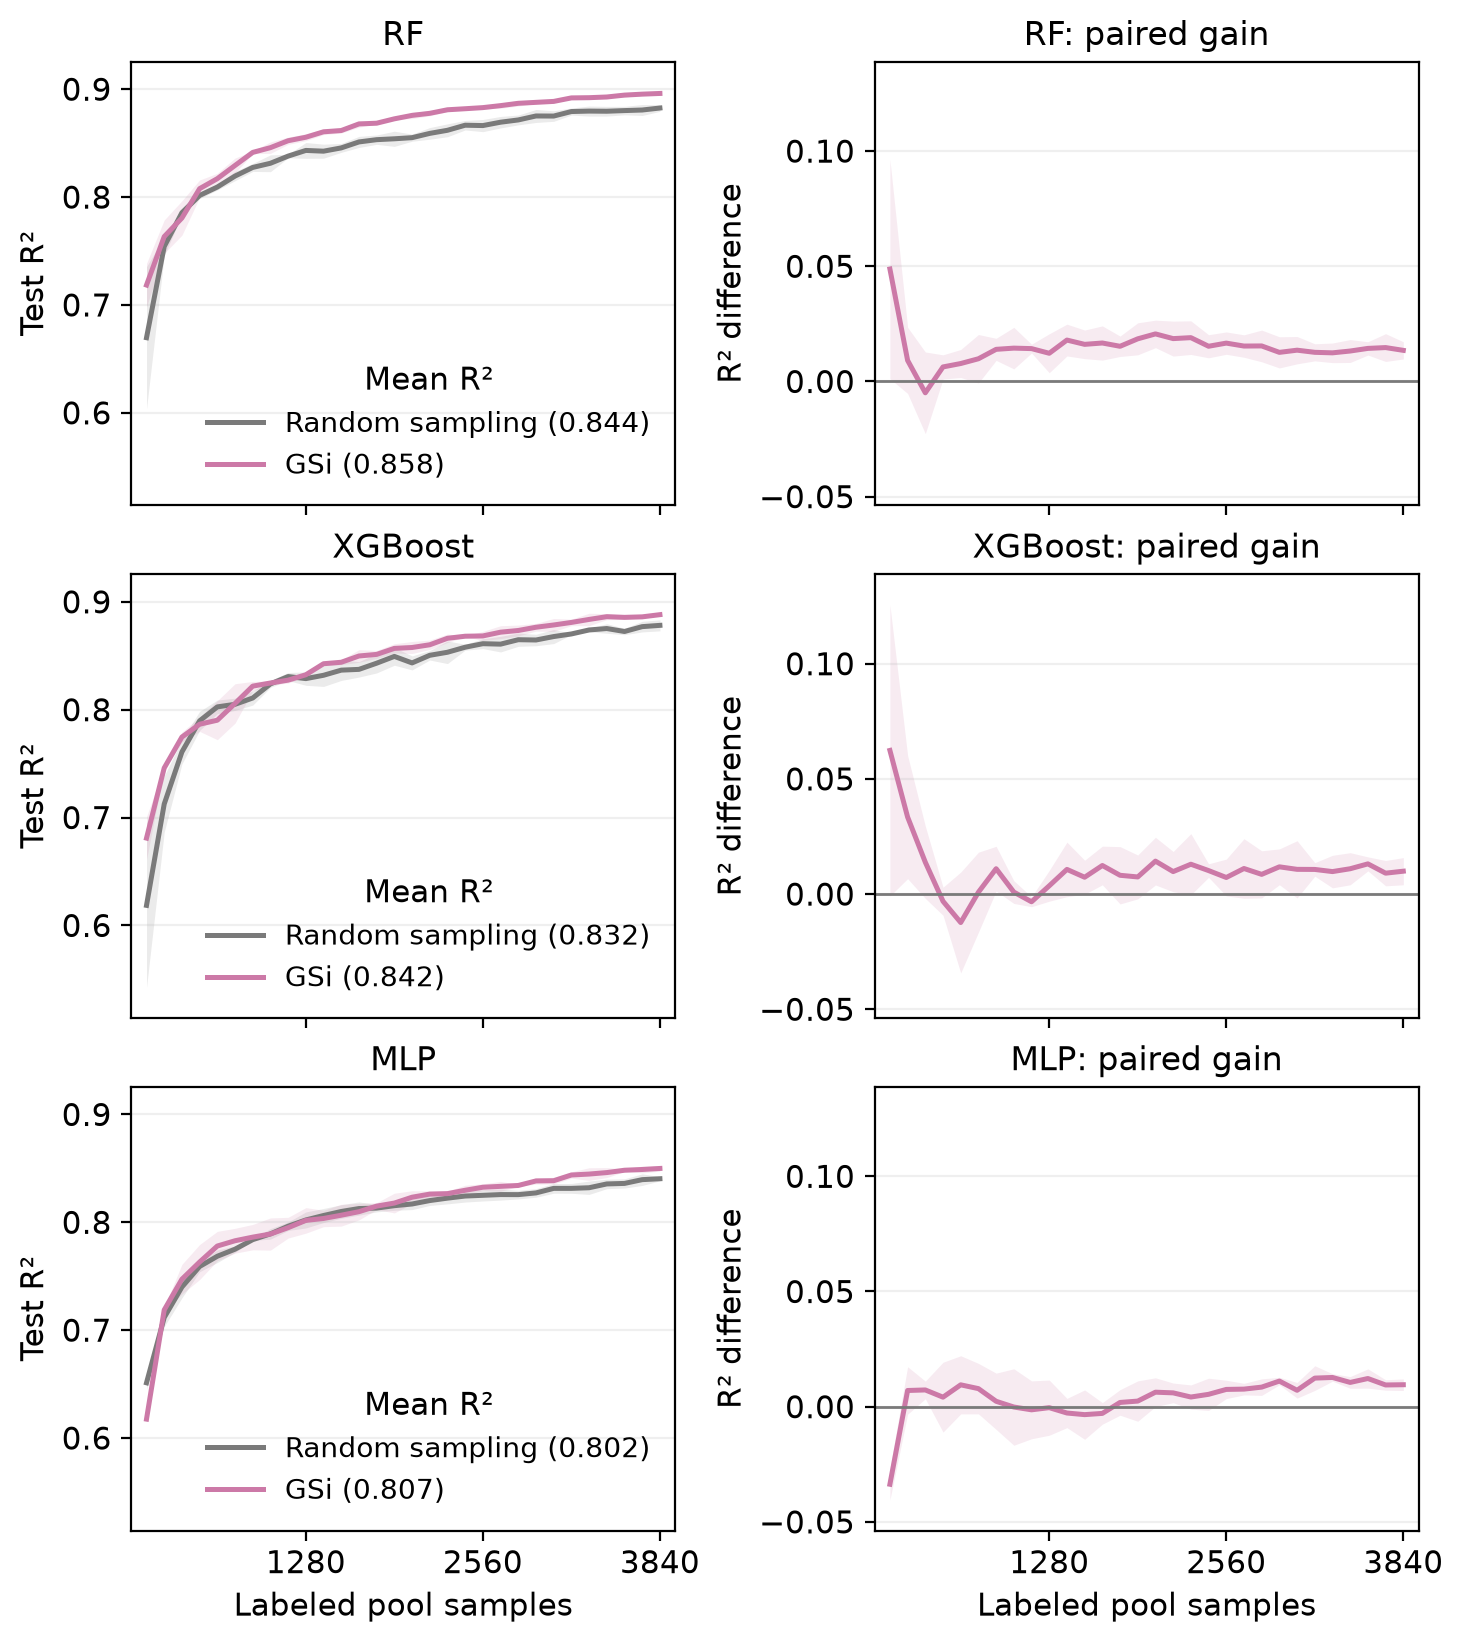

In [9]:
strategy_colors = {"Random sampling": "#7A7A7A", "GSi": "#CC79A7"}
# Start at the first acquisition. Without labels, every model predicts zero.
x = label_counts[1:]
fig, axes = plt.subplots(
    len(regressor_dict),
    2,
    figsize=(7.2, 2.5 * len(regressor_dict) + 0.6),
    sharex=True,
    sharey="col",
    squeeze=False,
    layout="constrained",
)

for row, reg_name in enumerate(regressor_dict):
    ax_score, ax_gain = axes[row]
    for qs_name in query_strategy_dict:
        color = strategy_colors[qs_name]
        scores = results[f"{reg_name}-{qs_name}"][:, 1:]
        mean = scores.mean(axis=0)
        std = scores.std(axis=0, ddof=1)
        ax_score.plot(
            x,
            mean,
            color=color,
            lw=1.8,
            label=f"{qs_name} ({mean.mean():.3f})",
        )
        ax_score.fill_between(
            x,
            mean - std,
            mean + std,
            color=color,
            alpha=0.15,
            linewidth=0,
        )

    if {"GSi", "Random sampling"}.issubset(query_strategy_dict):
        gains = (
            results[f"{reg_name}-GSi"] - results[f"{reg_name}-Random sampling"]
        )[:, 1:]
        mean = gains.mean(axis=0)
        std = gains.std(axis=0, ddof=1)
        ax_gain.plot(x, mean, color=strategy_colors["GSi"], lw=1.8)
        ax_gain.fill_between(
            x,
            mean - std,
            mean + std,
            color=strategy_colors["GSi"],
            alpha=0.15,
            linewidth=0,
        )
        ax_gain.axhline(0, color=strategy_colors["Random sampling"], lw=1)
        ax_gain.set(title=f"{reg_name}: paired gain", ylabel="R² difference")
    else:
        ax_gain.set_visible(False)
    ax_score.set(title=reg_name, ylabel="Test R²")
    ax_score.legend(loc="lower right", title="Mean R²", frameon=False)

ticks = label_counts[np.linspace(0, n_cycles, 4, dtype=int)[1:]]
for ax in axes.flat:
    ax.set_xticks(ticks)
    ax.margins(x=0.03, y=0.08)
    ax.grid(axis="y", alpha=0.2)
for ax in axes[-1]:
    ax.set_xlabel("Labeled pool samples")

plt.show()

Positive paired gains identify budgets where GSi's mean test R² exceeds random sampling for that model. Inspect their size and variation alongside the absolute scores: a strategy advantage and an accurate regression model are different findings. Compare models through their R² curves and legend means, and use the gain panels to see whether an advantage persists throughout acquisition.

These results concern one fixed split, candidate cap, batch size, backend, and set of model parameters. Differences between model families also reflect fitting procedures and training effort. Extend the protocol to repeated data splits using the [evaluation study](04_pool_simple_evaluation_study.ipynb) before using it to select a model or strategy for another task.

## Adapt the Study

Replace an estimator inside `SklearnRegressor`, or replace `MLPModule` with your own PyTorch network inside `SkorchRegressor`. Compare strategies with each model's parameters held fixed. Vary `n_candidates` to study the selection cost, or change the batch size while keeping the total annotation budget comparable. For a real annotation workflow, replace the oracle lookup with requested numerical labels and leave unlabeled entries as missing. If some labels are unavailable, track actually acquired labels with `labeled_indices(y)` instead of the fixed `label_counts` schedule used here.